<a href="https://www.kaggle.com/code/lalit7881/top-instagram-accounts-daily-eda-100?scriptVersionId=364520249" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")
# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/arkhiplisitsa/instagram-top-accounts/daily.csv
/kaggle/input/datasets/arkhiplisitsa/instagram-top-accounts/latest.csv


## Loading libraries

In [2]:
# Imports and warning suppression
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')  # required backend
import matplotlib.pyplot as plt
plt.switch_backend('Agg')
%matplotlib inline

import seaborn as sns

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score

# Helper function to resolve data file
DATA_ROOTS = [
    Path('/kaggle/input'),
    Path('/kaggle/input'),
    Path('/kaggle/input/datasets')
]

def resolve_data_file(file_name=None, suffixes=None):
    suffixes = tuple(suffixes or [])
    for root in DATA_ROOTS:
        if not root.exists():
            continue
        matches = [p for p in root.rglob('*') if p.is_file()]
        if file_name:
            exact = [p for p in matches if p.name == file_name]
            if exact:
                return exact[0]
        if suffixes:
            typed = [p for p in matches if p.suffix.lower() in suffixes]
            if typed:
                return typed[0]
    raise FileNotFoundError(f'Could not resolve data file: {file_name or suffixes}')

sns.set(style='whitegrid')

## Loading dataset

In [3]:
try:
    latest_file = resolve_data_file(file_name='latest.csv')
    latest_df = pd.read_csv(latest_file, encoding='utf-8')
    print(f'Loaded latest.csv from: {latest_file}')
except Exception as e:
    print('Error loading latest.csv:', e)

# Load daily.csv
try:
    daily_file = resolve_data_file(file_name='daily.csv')
    daily_df = pd.read_csv(daily_file, encoding='utf-8')
    print(f'Loaded daily.csv from: {daily_file}')
except Exception as e:
    print('Error loading daily.csv:', e)

Loaded latest.csv from: /kaggle/input/datasets/arkhiplisitsa/instagram-top-accounts/latest.csv
Loaded daily.csv from: /kaggle/input/datasets/arkhiplisitsa/instagram-top-accounts/daily.csv


In [4]:
# Combine the two datasets for cleaning purposes
latest_df['dataset'] = 'latest'
daily_df['dataset'] = 'daily'

df = pd.concat([latest_df, daily_df], ignore_index=True)
print('Combined dataset shape:', df.shape)

# Convert 'date' column to datetime. If an error occurs, note that the format may be irregular.
try:
    df['date'] = pd.to_datetime(df['date'], errors='coerce')
    if df['date'].isnull().any():
        print('Warning: Some dates could not be converted and are set to NaT.')
except Exception as e:
    print('Error parsing dates:', e)

# Check for missing values
missing_values = df.isnull().sum()
print('Missing values per column:')
print(missing_values)

# Handle duplicate records
duplicates = df.duplicated().sum()
print('Number of duplicate records:', duplicates)

if duplicates > 0:
    df = df.drop_duplicates()
    print('Duplicates dropped. New shape:', df.shape)

Combined dataset shape: (50069, 11)
Missing values per column:
date             0
username         0
followers        0
name             0
category         0
country       1308
type             0
rank             0
also_in      48985
countries     1308
dataset          0
dtype: int64
Number of duplicate records: 0


## EDA

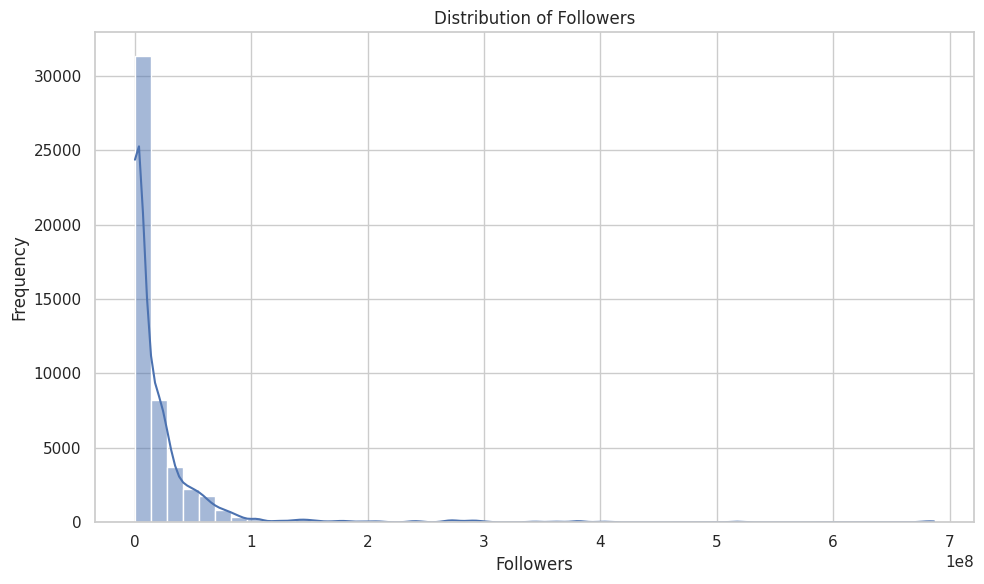

In [5]:
# Distribution of followers using a histogram
plt.figure(figsize=(10, 6))
sns.histplot(df['followers'], bins=50, kde=True)
plt.title('Distribution of Followers')
plt.xlabel('Followers')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

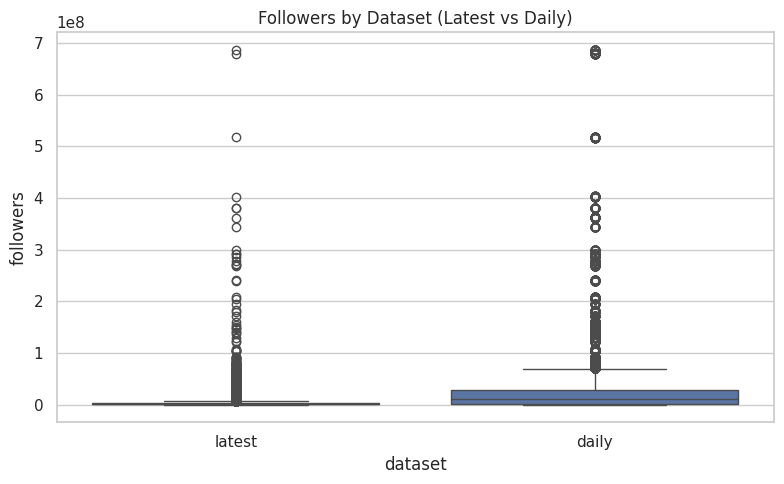

In [6]:
plt.figure(figsize=(8, 5))
sns.boxplot(x='dataset', y='followers', data=df)
plt.title('Followers by Dataset (Latest vs Daily)')
plt.tight_layout()
plt.show()

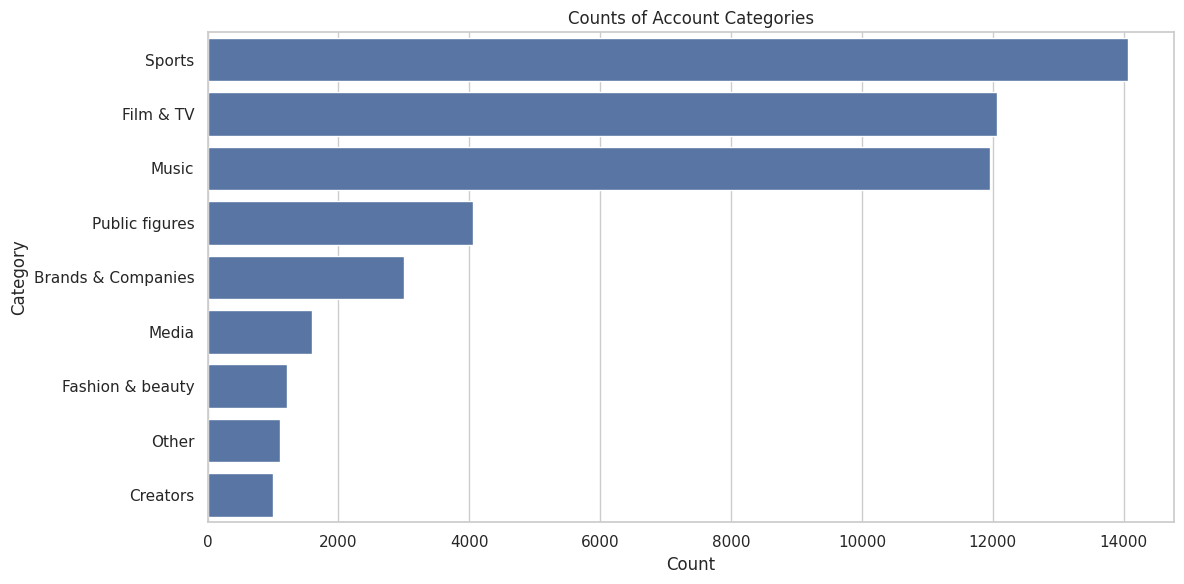

In [7]:
plt.figure(figsize=(12, 6))
sns.countplot(y='category', data=df, order=df['category'].value_counts().index)
plt.title('Counts of Account Categories')
plt.xlabel('Count')
plt.ylabel('Category')
plt.tight_layout()
plt.show()

In [8]:
# Pair plot for numerical features (only if there are 4 or more numeric columns)
numeric_df = df.select_dtypes(include=[np.number])
if numeric_df.shape[1] >= 4:
    sns.pairplot(numeric_df)
    plt.suptitle('Pair Plot of Numerical Features', y=1.02)
    plt.show()
else:
    print('Not enough numeric columns for a pair plot.')

# Correlation heatmap if there are 4 or more numeric columns
if numeric_df.shape[1] >= 4:
    plt.figure(figsize=(10, 8))
    corr = numeric_df.corr()
    sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
    plt.title('Correlation Heatmap of Numerical Features')
    plt.tight_layout()
    plt.show()
else:
    print('Not enough numeric columns for a detailed correlation heatmap.')

Not enough numeric columns for a pair plot.
Not enough numeric columns for a detailed correlation heatmap.


## Feature engineering

In [9]:
# Prepare features for prediction
predict_df = df.copy()

# We will use 'rank' and 'category'. Additional features could be added.
features = ['rank', 'category']
target = 'followers'

# One-hot encode the categorical 'category' column
predict_df = pd.get_dummies(predict_df, columns=['category'], drop_first=True)

# Final feature list: include rank and new one-hot encoded columns
feature_cols = [col for col in predict_df.columns if col.startswith('rank') or col.startswith('category_')]

# Ensure that we have the necessary columns
if 'rank' not in feature_cols:
    feature_cols = ['rank'] + feature_cols

X = predict_df[feature_cols]
y = predict_df[target]

# Split into train and test sets for validation
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Build a Random Forest Regressor as the predictor
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

# Evaluate the model using R2 score
r2 = r2_score(y_test, y_pred)
print(f'Random Forest Regressor R2 score: {r2:.2f}')

# Plotting feature importances
importances = model.feature_importances_
indices = np.argsort(importances)[::-1]

Random Forest Regressor R2 score: 1.00


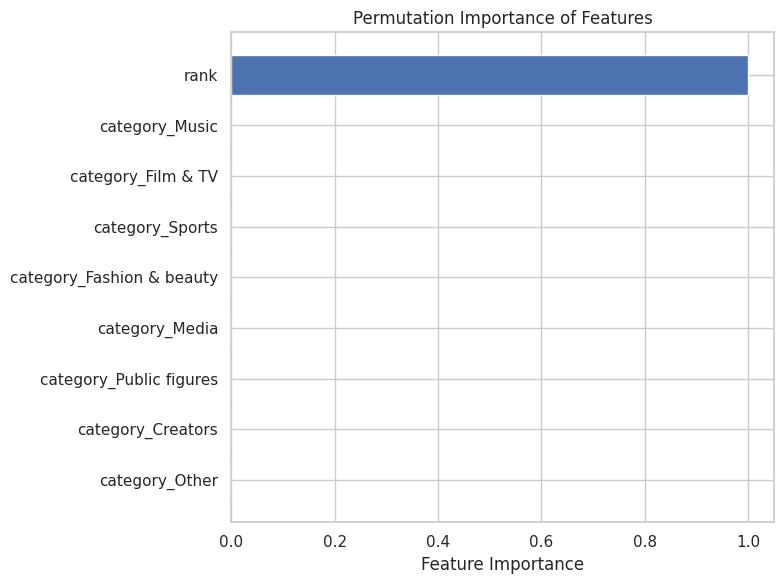

In [10]:
plt.figure(figsize=(8, 6))
plt.barh(range(len(indices)), importances[indices], color='b', align='center')
plt.yticks(range(len(indices)), [feature_cols[i] for i in indices])
plt.gca().invert_yaxis()
plt.xlabel('Feature Importance')
plt.title('Permutation Importance of Features')
plt.tight_layout()
plt.show()

## Thank you..pls upvote!!!!!!!